# Task 13, Notebook 08: Candidate models, cross-validation and tuning log

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 13: Attrition model v2: beat the baseline honestly  
**Objective:** Train the candidates, compare them on identical folds and keep a complete log of a small, controlled tuning search.  
**Workflow stages covered in this notebook:** 25, 26, 27, 28 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


In [2]:
import joblib
from cortexhr.phase3.attrition import v2 as V, train as TR
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr import config as C, features as F
d = V.load_training(); X, y, Xtr, Xte, ytr, yte, folds, dfm = d['X'], d['y'], d['Xtr'], d['Xte'], d['ytr'], d['yte'], d['folds'], d['df']
bench = read_csv('baseline_benchmarks')
print('model frame:', dfm.shape, '| inputs:', X.shape[1], '| train/test:', len(Xtr), '/', len(Xte), '| folds:', len(folds), '| base rate: %.3f' % y.mean())

model frame: (2383, 56) | inputs: 43 | train/test: 1906 / 477 | folds: 5 | base rate: 0.146


## Stage 25: Model Selection and Justification

*What this stage is for:* Why these candidate methods.

Candidates: the Phase 1 logistic regression (baseline), the Phase 1 random forest, a gradient-boosting model (scikit-learn `HistGradientBoostingClassifier`, shallow trees, strong regularisation) and an equal-weight blend of logistic regression and gradient boosting (no weight search, so no weight overfitting). LightGBM and XGBoost are the programme's named libraries; they are used automatically when installed.

In [3]:
print('optional libraries in this environment:', V.optional_libs()); print('-> LightGBM / XGBoost not installed here: HistGradientBoosting is the documented substitute (same algorithm family, histogram gradient boosting).')

optional libraries in this environment: {'lightgbm': None, 'xgboost': None, 'shap': None}
-> LightGBM / XGBoost not installed here: HistGradientBoosting is the documented substitute (same algorithm family, histogram gradient boosting).


## Stage 26: Model Training

*What this stage is for:* Fit the candidates.

Fit each candidate on the training part and compare with its cross-validation score. A large gap between training and validation scores would signal overfitting.

In [4]:
from sklearn.metrics import roc_auc_score
models = {'Logistic Regression (balanced) [baseline]': V.baseline_models()['Logistic Regression (balanced)'], 'Random Forest (300, balanced) [baseline]': V.baseline_models()['Random Forest (300, balanced)'],
          'HistGradientBoosting default': V.wrap(V.make_hgb())}
rows = []
for k, m in models.items():
    from sklearn.base import clone
    f = clone(m).fit(Xtr, ytr); rows.append({'model': k, 'train_roc_auc': roc_auc_score(ytr, f.predict_proba(Xtr)[:, 1])})
pd.DataFrame(rows).round(3)

                                       model  train_roc_auc
0  Logistic Regression (balanced) [baseline]          0.840
1   Random Forest (300, balanced) [baseline]          1.000
2               HistGradientBoosting default          0.945

## Stage 27: Cross-Validation

*What this stage is for:* Repeat the evaluation on several splits to see the spread.

Per-fold metrics on the **same five folds** for every model. Spread across folds is as important as the mean.

In [5]:
log, tune_folds = V.run_tuning(Xtr, ytr, folds); params = V.best_params(log)
cands = {**models, 'HistGradientBoosting tuned': V.wrap(V.make_hgb(**params)), 'attrition-v2 candidate: LR + tuned HGB blend': V.make_v2(params)}
ft = pd.concat([V.fold_table(m, Xtr, ytr, folds, k) for k, m in cands.items()], ignore_index=True)
summ = V.summarise(ft); summ[['model', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'pr_auc_sd', 'precision_mean', 'recall_mean', 'f1_mean', 'balanced_accuracy_mean', 'brier_mean']].round(3)

                                          model  roc_auc_mean  roc_auc_sd  pr_auc_mean  pr_auc_sd  precision_mean  recall_mean  f1_mean  balanced_accuracy_mean  brier_mean
0                  HistGradientBoosting default         0.680       0.017        0.294      0.034           0.274        0.484    0.350                   0.632       0.179
1                    HistGradientBoosting tuned         0.695       0.021        0.310      0.055           0.258        0.563    0.354                   0.643       0.198
2     Logistic Regression (balanced) [baseline]         0.709       0.021        0.325      0.051           0.262        0.584    0.361                   0.650       0.200
3      Random Forest (300, balanced) [baseline]         0.700       0.025        0.316      0.067           0.474        0.093    0.155                   0.537       0.123
4  attrition-v2 candidate: LR + tuned HGB blend         0.716       0.017        0.325      0.052           0.276        0.584    0.375     

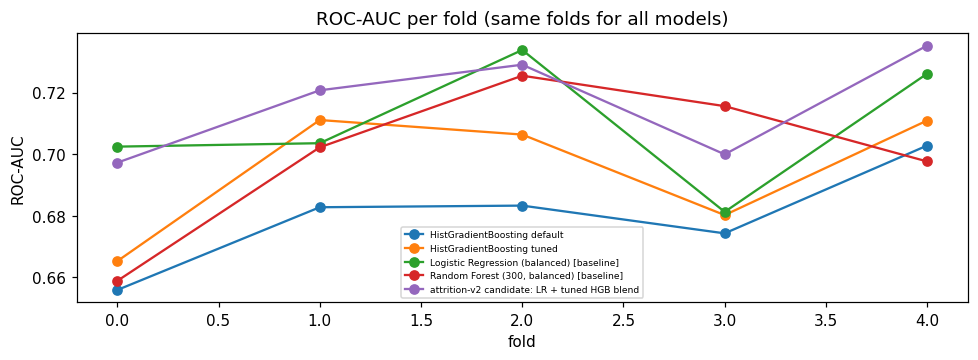

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4)); piv = ft.pivot(index='fold', columns='model', values='roc_auc'); piv.plot(ax=ax, marker='o'); ax.set_ylabel('ROC-AUC'); ax.legend(fontsize=6); ax.set_title('ROC-AUC per fold (same folds for all models)'); plt.tight_layout(); plt.savefig(P.FIGURES / 'task13_fold_roc_auc.png', dpi=130, bbox_inches='tight')

## Stage 28: Hyperparameter Tuning

*What this stage is for:* A small, logged search; no tuning on the test set.

16 settings of a deliberately small grid (shallow trees, strong regularisation, small learning rates). Selection uses mean cross-validation PR-AUC on the training part only; the test set is untouched.

In [7]:
save_table(log, P.task_dir(13) / 'tuning_log.csv'); log[['experiment_id', 'params', 'roc_auc_mean', 'roc_auc_sd', 'pr_auc_mean', 'decision']].round(3)

   experiment_id                                                                                                                            params  roc_auc_mean  roc_auc_sd  pr_auc_mean                           decision
0         HGB-00   {'learning_rate': 0.03, 'max_iter': 250, 'max_depth': 2, 'max_leaf_nodes': 4, 'min_samples_leaf': 40, 'l2_regularization': 1.0}         0.694       0.022        0.309                       not selected
1         HGB-01   {'learning_rate': 0.03, 'max_iter': 250, 'max_depth': 3, 'max_leaf_nodes': 8, 'min_samples_leaf': 40, 'l2_regularization': 1.0}         0.684       0.018        0.299                       not selected
2         HGB-02   {'learning_rate': 0.05, 'max_iter': 150, 'max_depth': 2, 'max_leaf_nodes': 4, 'min_samples_leaf': 40, 'l2_regularization': 1.0}         0.695       0.021        0.310  selected (highest mean CV PR-AUC)
3         HGB-03   {'learning_rate': 0.05, 'max_iter': 150, 'max_depth': 3, 'max_leaf_nodes': 8, 'min_samples_leaf':

In [8]:
top = log.sort_values('pr_auc_mean', ascending=False).head(5)
print('selected:', log.loc[log.decision.str.startswith('selected'), 'experiment_id'].iloc[0], params)
print('top-5 settings span %.3f in mean PR-AUC and %.3f in ROC-AUC, while the fold-to-fold sd is about %.3f -> the optimum is flat; extra tuning would only fit noise.' % (top.pr_auc_mean.max() - top.pr_auc_mean.min(), top.roc_auc_mean.max() - top.roc_auc_mean.min(), log.roc_auc_sd.mean()))

selected: HGB-02 {'learning_rate': 0.05, 'max_iter': 150, 'max_depth': 2, 'max_leaf_nodes': 4, 'min_samples_leaf': 40, 'l2_regularization': 1.0}
top-5 settings span 0.007 in mean PR-AUC and 0.009 in ROC-AUC, while the fold-to-fold sd is about 0.019 -> the optimum is flat; extra tuning would only fit noise.
